<a href="https://colab.research.google.com/github/SayyadRizwan/GAN-based-Oral-Cancer-detection-with-GraphRag/blob/main/ORAL_CANCER_DETECTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install kagglehub
!pip install -q kagglehub

# Import library
import kagglehub

# Download the latest version of the dataset
path = kagglehub.dataset_download("ashenafifasilkebede/dataset")

# Print the download location
print("Path to dataset files:", path)

100%|██████████| 2.93G/2.93G [00:33<00:00, 94.8MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ashenafifasilkebede/dataset/versions/1


In [ ]:
import tensorflow as tf
import os

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dir = os.path.join(path, "train")
test_dir = os.path.join(path, "test")

# Training dataset (80%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Validation dataset (20%)
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Test dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
print("Classes:", class_names)

Found 4946 files belonging to 2 classes.
Using 3957 files for training.
Found 4946 files belonging to 2 classes.
Using 989 files for validation.
Found 126 files belonging to 2 classes.
Classes: ['Normal', 'OSCC']


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [ ]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.2),
])

In [ ]:
from tensorflow.keras.applications import EfficientNetB0

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224,224,3)
)

base_model.trainable = False

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    BatchNormalization
)

inputs = Input(shape=(224,224,3))

x = data_augmentation(inputs)

x = tf.keras.applications.efficientnet.preprocess_input(x)

x = base_model(x, training=False)

x = GlobalAveragePooling2D()(x)

x = BatchNormalization()(x)

x = Dropout(0.4)(x)

x = Dense(256, activation='relu')(x)

x = Dropout(0.3)(x)

outputs = Dense(1, activation='sigmoid')(x)

model = Model(inputs, outputs)

In [ ]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,382,884 (16.72 MB)

 Trainable params: 330,753 (1.26 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

callbacks = [

    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-6
    ),

    ModelCheckpoint(
        "best_oral_cancer_model.keras",
        save_best_only=True
    )
]

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20
124/124 ━━━━━━━━━━━━━━━━━━━━ 62s 352ms/step - accuracy: 0.6280 - auc: 0.6950 - loss: 0.8432 - precision: 0.5901 - recall: 0.8485 - val_accuracy: 0.8119 - val_auc: 0.8931 - val_loss: 0.4868 - val_precision: 0.8658 - val_recall: 0.7634 - learning_rate: 1.0000e-04
Epoch 2/20
124/124 ━━━━━━━━━━━━━━━━━━━━ 71s 306ms/step - accuracy: 0.7412 - auc: 0.8122 - loss: 0.5671 - precision: 0.7294 - recall: 0.7705 - val_accuracy: 0.8382 - val_auc: 0.9221 - val_loss: 0.3875 - val_precision: 0.9009 - val_recall: 0.7805 - learning_rate: 1.0000e-04
Epoch 3/20
124/124 ━━━━━━━━━━━━━━━━━━━━ 41s 330ms/step - accuracy: 0.7698 - auc: 0.8526 - loss: 0.4973 - precision: 0.7737 - recall: 0.7655 - val_accuracy: 0.8534 - val_auc: 0.9355 - val_loss: 0.3346 - val_precision: 0.9041 - val_recall: 0.8092 - learning_rate: 1.0000e-04
Epoch 4/20
124/124 ━━━━━━━━━━━━━━━━━━━━ 41s 331ms/step - accuracy: 0.7981 - auc: 0.8769 - loss: 0.4521 - precision: 0.7994 - recall: 0.7982 - val_accuracy: 0.8675 - val_auc: 0.9425 

In [ ]:
base_model.trainable = True

# Freeze the first 100 layers
for layer in base_model.layers[:100]:
    layer.trainable = False

model.compile(
    optimizer=Adam(1e-5),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(),
        tf.keras.metrics.Recall(),
        tf.keras.metrics.AUC()
    ]
)

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 74s 355ms/step - accuracy: 0.6482 - auc: 0.7164 - loss: 0.7614 - precision: 0.6288 - recall: 0.7307 - val_accuracy: 0.8402 - val_auc: 0.9196 - val_loss: 0.3596 - val_precision: 0.8466 - val_recall: 0.8531 - learning_rate: 1.0000e-05
Epoch 2/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 82s 358ms/step - accuracy: 0.7207 - auc: 0.7939 - loss: 0.6266 - precision: 0.7017 - recall: 0.7720 - val_accuracy: 0.8119 - val_auc: 0.9028 - val_loss: 0.4031 - val_precision: 0.7986 - val_recall: 0.8626 - learning_rate: 1.0000e-05
Epoch 3/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 43s 347ms/step - accuracy: 0.7400 - auc: 0.8225 - loss: 0.5741 - precision: 0.7228 - recall: 0.7821 - val_accuracy: 0.8069 - val_auc: 0.8966 - val_loss: 0.4167 - val_precision: 0.7916 - val_recall: 0.8626 - learning_rate: 2.0000e-06
Epoch 4/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 82s 350ms/step - accuracy: 0.7493 - auc: 0.8306 - loss: 0.5568 - precision: 0.7296 - recall: 0.7957 - val_accuracy: 0.8079 - val_auc: 0.8981 

In [ ]:
results = model.evaluate(test_ds)

print("Loss      :", results[0])
print("Accuracy  :", results[1])
print("Precision :", results[2])
print("Recall    :", results[3])
print("AUC       :", results[4])

4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.7460 - auc: 0.7798 - loss: 0.5723 - precision: 0.8706 - recall: 0.7789
Loss      : 0.5722758769989014
Accuracy  : 0.7460317611694336
Precision : 0.8705882430076599
Recall    : 0.7789473533630371
AUC       : 0.779796302318573


In [ ]:
model.save("oral_cancer_efficientnetb0.keras")

In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

img_path = "/content/WhatsApp Image 2026-08-05 at 11.33.56 PM.jpeg"   # Change to your image path

img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
prediction = model.predict(img_array)[0][0]

print(prediction)
if prediction >= 0.5:
    print("Prediction: OSCC")
    print(f"Confidence: {prediction*100:.2f}%")
else:
    print("Prediction: Normal")
    print(f"Confidence: {(1-prediction)*100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
0.98480844
Prediction: OSCC
Confidence: 98.48%


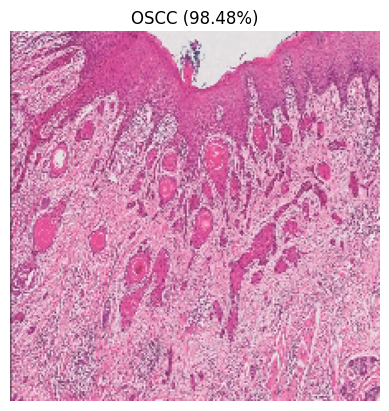

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(img)
plt.axis("off")

if prediction >= 0.5:
    plt.title(f"OSCC ({prediction*100:.2f}%)")
else:
    plt.title(f"Normal ({(1-prediction)*100:.2f}%)")

plt.show()